# Line-by-line Search

You have GitHub's Terms of Service and a plain-language question about it. You need the
lines that answer the question and a way to detect when the document has no answer. You
end up with `find()`, which returns the `exists` probability and one relevance score per
line.

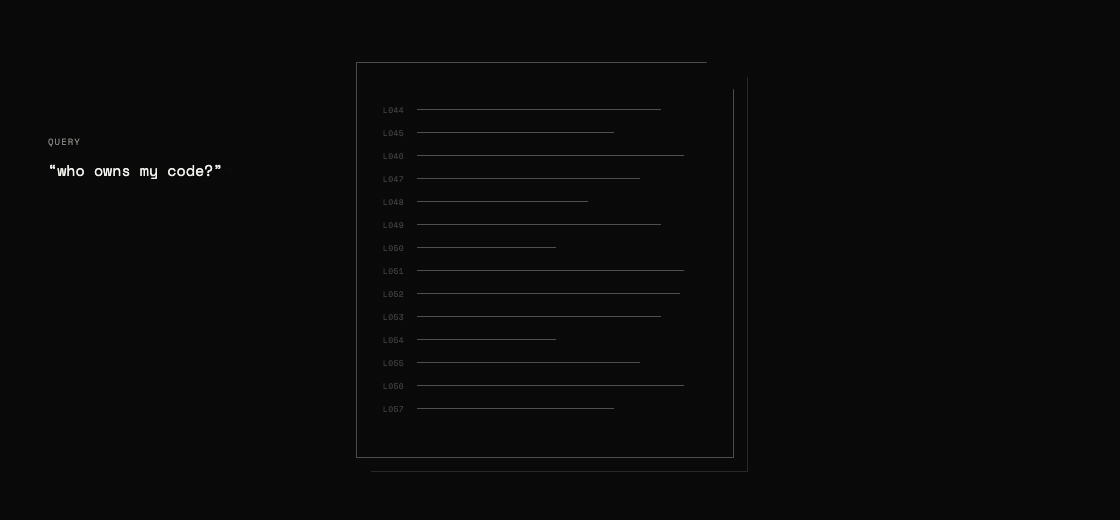

The search has three parts:

1. Tag each line with an ID so Jev can point to it.
2. Use a `Choice` question to rank those line IDs by how well they answer the query.
3. In the same request, use a `Noul` question to check whether the document contains an
   answer at all.

## Setup

### Install the dependencies

```bash
pip install ipython 'cooksafe>=0.3.0,<0.4.0'
```

The code replays saved answers, so it runs as published without an API key. To change a
request, [create a TypeSafe API key](https://console.typesafe.ai/keys) and set
`TYPESAFE_API_KEY`; in Colab, add it in the Secrets panel.

### Create the script

Start `semantic_search.py` with the imports and the client:

In [ ]:
%pip install -q 'typesafe-sdk>=0.7.0' ipython 'cooksafe>=0.3.0,<0.4.0'

In [1]:
import os
import urllib.request
from pathlib import Path

from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Choice, Noul, NoulCriteria, TypeSafeClient

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live

# The keys this cookbook uses. In Colab, keys saved in the Secrets panel are copied in here.
KEYS = ["TYPESAFE_API_KEY"]
try:
    from google.colab import userdata
except ImportError:  # not in Colab
    userdata = None
for key in KEYS:
    if userdata is not None and key not in os.environ:
        try:
            os.environ[key] = userdata.get(key)
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            pass  # not saved, or this notebook may not read it

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"), timeout=120.0
)

In [2]:
EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/semantic_find"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("semantic_find_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Step 1: tag every line with an ID

The test document is GitHub's Terms of Service, split into 218 clauses, so every search
result points to one quotable line.

In [3]:
DOCUMENT_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/cookbooks/semantic_find/github-tos.txt"
)


@json_cache
def fetch_document(url: str) -> str:
    request = urllib.request.Request(
        url, headers={"User-Agent": "typesafe-cookbook/1.0"}
    )
    with urllib.request.urlopen(request) as response:
        return response.read().decode()


LINES = fetch_document(DOCUMENT_URL).splitlines()

The cache prevents repeated downloads.

Now prefix each line with a short ID and join the lines back into one document. The model
uses these IDs to point to its answer.

In [4]:
def line_id(i: int) -> str:
    return f"L{i:03d}"


DOCUMENT = "\n".join(f"{line_id(i)}| {line}" for i, line in enumerate(LINES))

`DOCUMENT` now looks like this:

```
L052| You own Your Content. If you post Content you did not create, you are responsible for...
L053| You grant us and other Users the licenses in Sections D.4–D.8. These licenses apply...
L054| 4. License Grant to Us
```

## Step 2: ask where the answer is

A `Choice` question returns a probability for every option. Use the line IDs as the
options.

In [5]:
def where_question(query: str) -> Choice:
    return Choice(
        instructions=f'Which line of the document contains the answer to: "{query}"?',
        criteria={line_id(i): None for i in range(len(LINES))},
    )

The option descriptions are `None` because the document already contains the text for each
ID. The query goes in `instructions`; the state stays unchanged between searches.

<Info> A `Choice` question accepts up to 255 options, so this recipe searches documents of
up to 255 lines in one request. Past that, search in two passes: one Choice question picks
a window
of lines, and a second ranks the lines inside it. </Info>

## Step 3: check whether an answer exists

Choice probabilities always add up to 1, so some line ranks first even when the document
doesn't answer the question.

In [6]:
def exists_question(query: str) -> Noul:
    return Noul(
        instructions=f'Does any line of the document address or answer: "{query}"?',
        criteria=NoulCriteria(
            true="At least one line of the document states or directly implies the answer",
            false="No line of the document addresses this",
        ),
    )

Unlike the Choice probabilities, the Noul probability doesn't depend on the other options,
so it can fall near zero when the document has no answer.

## Step 4: send both questions in one request

Both questions go in one `system_one` call, so the document is sent once.

```mermaid
flowchart LR
    doc["tagged document<br/><i>lines with IDs</i>"]
    query["user question"]

    subgraph request["one TypeSafe request · both questions see the full document"]
        direction TB
        shared["shared document<br/>and user question"]
        choice["<b>one Choice question</b><br/>which line answers<br/>the question?"]
        noul["<b>one Noul question</b><br/>does the document contain<br/>an answer at all?"]
        relevance["probability<br/>for every line ID"]
        exists["exists noul<br/>0 to 1"]
        shared --> choice
        shared --> noul
        choice --> relevance
        noul --> exists
    end

    rank["sort lines by<br/>Choice probability"]
    verdict["apply verdict<br/>answered · partial · absent"]
    out["ranked evidence<br/>and document verdict"]

    doc --> shared
    query --> shared
    relevance --> rank
    exists --> verdict
    rank --> out
    verdict --> out
```

In [7]:
@json_cache
def _find(
    state: str,
    where: Choice,
    exists: Noul,
    model: str,
) -> dict:
    response = client.system_one(
        state=state,
        questions={"where": where, "exists": exists},
        model=model,
    )
    probabilities = response.answers["where"].probabilities
    return {
        "exists": response.answers["exists"].noul,
        "relevance": [probabilities.get(line_id(i), 0.0) for i in range(len(LINES))],
    }


def find(query: str) -> dict:
    return _find(
        DOCUMENT,
        where_question(query),
        exists_question(query),
        model=TYPESAFE_MODEL,
    )

The `relevance` list keeps one score per line, in document order.

## Step 5: read the result

The `exists` probability becomes one of three verdicts, the middle one for partial
answers. The ranking prints as a bar chart.

In [8]:
FOUND, ABSENT = 0.7, 0.35  # `exists` cutoffs for answered and not in this document


def verdict(exists: float) -> str:
    if exists >= FOUND:
        return "answered in this document"
    return "not in this document" if exists < ABSENT else "partially addressed"


def show(query: str, top: int = 4) -> dict:
    result = find(query)
    print(f'"{query}"')
    print(f"  exists {result['exists']:.2f} -> {verdict(result['exists'])}")
    ranked = sorted(
        range(len(LINES)), key=lambda i: result["relevance"][i], reverse=True
    )
    for i in ranked[:top]:
        bar = "#" * max(1, round(result["relevance"][i] * 12))
        preview = LINES[i][:58].rstrip()
        print(f"  {line_id(i)}  {result['relevance'][i]:.2f}  {bar:<12}  {preview}")
    return result

Tune these thresholds on your own documents before using them in production.

## Step 6: run the search

Ask two questions that have direct answers, one that has a partial answer, and one that has
no answer.

In [9]:
print(f"{len(LINES)} lines, {len(DOCUMENT):,} characters\n")
show("who owns the code I upload?")
print()
show("can GitHub kick me off the platform without warning?")
print()
show("do I have to take disputes to arbitration?", top=2)
print()
show("can I join a class action lawsuit against GitHub?", top=2)

218 lines, 43,980 characters

"who owns the code I upload?"
  exists 0.99 -> answered in this document
  L052  0.77  #########     You own Your Content. If you post Content you did not crea
  L046  0.12  #             Short version: You own content you create, but you allow u
  L051  0.06  #             3. Ownership and License Grants
  L053  0.05  #             You grant us and other Users the licenses in Sections D.4–

"can GitHub kick me off the platform without warning?"
  exists 0.98 -> answered in this document
  L168  0.96  ############  GitHub has the right to suspend or terminate your access t
  L167  0.04  #             3. GitHub May Terminate
  L000  0.00  #             Effective date: April 27, 2026 · A. Definitions
  L001  0.00  #             Short version: We use these basic terms throughout the agr

"do I have to take disputes to arbitration?"
  exists 0.65 -> partially addressed
  L205  0.80  ##########    Except to the extent applicable law provides otherwise, th
  L20

## What the scores mean

The first two queries return direct answers and the source lines needed to verify them.

- **Arbitration:** The Terms never mention arbitration. The top line, at 0.80, is the
  governing-law clause, which sends disputes to the courts in San Francisco. `exists` is
  0.65, so the result is **partially addressed**.
- **Class action:** The Terms never mention class actions. The ranking still puts the
  governing-law clause first, at 0.23, because a ranking always has a top line. `exists`
  is 0.05, so the result is **not in this document**.

The ranking tells you where to look; the `exists` score tells you whether the result
answers the question.

To search your own document, swap `DOCUMENT_URL`; every other line of the script works off
`LINES`.

## Open it in the playground

The link holds the tagged contract and both questions for "who owns the code I upload?".

In [10]:
QUERY = "who owns the code I upload?"
playground_link = make_playground_link(
    DOCUMENT, {"where": where_question(QUERY), "exists": exists_question(QUERY)}
)
display(Markdown(f"🔗 [Open in the TypeSafe playground]({playground_link})"))

🔗 [Open in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIAMgAxkA++AogGY0JQoCWAbgvmAIYoIECCABwBOTADb4ATAHYANJJISAbPgDt+PgDp8AEQQ0mSJswhIAzgB0kpEgEZKAZQAWEISnxshppiYIB1djCm7CiOCEH4AEacXlD4PEJwpnGOQhAwAObOMG4h7JzpQggIiKhynEhgyQgAnviOnGz4pgIMTPqxiOUG6aZaAJppTVmilQDWSBAA7viT9W6T7J1IM6HLC-iB7AicUI74EDRVcQgJvfhooYUA5EkTbukQ3XEQkXnHpm4m+EZyEdnfKBuTWYonEmxoMHEBhoLjg3G8SA0lmsEkofGW5hAfCgUDSqEx+EKwjCyBQSWqaSE+FECHSnHEhVE8JMpkcTAEMyMewA4kYABIwCJaPj4QA4BAAFE6mEz09Q4vEoQC4BISEMSgqgkuVvhVWEwwDBZQBVIJCQCYBJrss4RAAvZnLFAvUQQdLa574cqVTZHewnFhMKB5CpNX1hd2a-DGk7m75gUlGWpfXkoAVCsUAeSEdMMtuMZmVnEKQwLCEqkxco2aO1DIW4+DhtQieVM0qgTG4Jc5IXdTW6NPwcZQCapky5+yQ7BcdZc7EjnhWJ0WkOYAj7s6SUC1uNBnAiLnb7qgqWbdfKtWEEAAVgwye7PkgA8L8JLPDLxNjcTBUPgN8tG93EHAjZUgc7pILUSDwEB+yHBmWZMDmCK9MiZAAMyUBc7CinwBRFCUSoqvQnhyFuNKMKwCCiNUcgOu6oJHPEiTESYYBGIhch3P6oa4qgnAGB2k6FIRyABpUBjJEwSSQLAeH4AAFLkYoYKc0H4D6Qh+gGyqTgpmJKYkmIAJSgZU9LiBAuTAS0QjwkgLpCJCYRyAIECiP6TChrJBhQKIMAsbZRxJimT4iCwOy1PYKDtnhZShWIO59rW6RcoKGi4nAAD0Xg8OlwisGFRkevg54iTAhRJDW8yLJwZ6Cq5rL4DQqRwHETCIG6zBtV8Cn+BEWUIFoACyEAfCplI9jwRUuW5obFu6sVMhECVuFJvRJSEKVpelG48A8IhhJlRgIAAtM5rlQNUSJWGQAAslCYnwACS+AAGLbCgpUIASSyamBDVvR9KmBYK+zAaV6h0GIbY8OVcwbEESRwrsfHUtsQiGP5k4Fsw7RtlCqAUa56TCcELxE+O1kTWm2QCNkcheT5fkukDET4AAwhAAhiOZcjs5zTpuHw2QHEwmBlEGp77BZf3cADepxvoHbRHDTyI2y44owW6MupjrhtG5soGDwoJMGTAaumNUnwKSdqXdYACslBYRDrntsq32gbUA61BVHBMIUjCUSD2osf7KCB9xKCpKIph0+uJiRy5NKVBEVFBxJGwVCc34QHAcBfBHUednsnBFVjqezAu+CYgXLlfdsZh1A0KvTskWr6DQg5FScAZfrJdskAApEZUzk6y7JBwpIiZDkLwh9eRxwkg+TFKSKkKV7WjPdpoRzY8XD3hOhyQIKKByAN-pHgcbjp1qfDO1Dh-4MzttkIod0gAAQggkXBQgfoIJMCwIA6z1yaFfSYxY5Amg0o5IO9AZZlRjPLdyJlNSiAEPUX439OBOUKP-SYchUaBx2AGZschJx-3pAaXM5DhwuDAEkScGDrLwyLj2OAcUqRLG6EhK6JApDv3ZvjfEwD3a4ljNRLAp8ODcBwRwaAVseI0O+HCImMd8AFE4Bg-06jpQdwgYUJyOxRjL3UYVcylwTzxFxgjTgsY5q8QWn2EIqQMh7AUmpGBL8SAAA5HbMxkMqUU-hAnGTFMaZUgks40QCfgB694NBlCSAsOiSsLZ+2vC4XRgovAsQLO5dRBcdgOiItSTiZgsnkIhgGUpy8NRi0qMUFcEBqhFF4dYAAnI7eJNN8LuwlhHVek5BnYCKqkP0sZKg0Vvk9V6CCEB03vAzJ4544ACDJGUFAkVdh4UKRAexYkKRgzLEICsAgqwNOzkgDwpg7R1AkiUi6yEbAkHflTFAvS67lCSGVZyZgZpBlMBkNRuZ1H018k8cRE5gJSzhNY+kcgyYnHbMnWoMyXr-UKC-Gwdhzg71FJ4zikS9BSnajvLRK5-R2l0eAyBYz9kwEYGYwFvpOJJHPBMjsKcn78kFIs7yEL-IuLSJkI4PU+phIll-H+4o8HuUAdi1E4STShNFAMGAoTCpqspMSwiZL2AGBYhMg04grLSiQExNZp5aEgzgghLqsN6hJD9H1Sok506BCeN1BAvVDpB0JQGAA3K3NwJCwisMnJsH6Z4sZrx3u+BUwbt61jnkyo4XoQIKQTZ+a+9od5WRhAkcoZsQJGCSBCe8oLHyzjrIENwf5aw0miG4GwKF8CtILIww4y8tD2BaK2WUDFbFooECuWohbIievHMeScDwPBIBktmjUckfTsB9GRL4H8+4GX4GAFiuZZR6VMAZbFaEq4gFnEdbkyBkU8EqEIngIiQHfLZvHVePsjlBwsVnTYc4YDNLsVAwUHDpHDMKPuYVbjvSsofM826eLMLisOrq0lMTeURGjAsX1E0nTbUVvcZKqY0qXNMlcx90joFssueefUaaOVy1RTy5MwNazb1caK712H+pxNDdHF4US5xoeYxEI6I8OxAoiJAOEBgu0aMI1oYjTRGXFySCWRlNs5PrSIznMJ5y1FaDWo4FK2c4BaAwuEI9tFpQaIgPOpjKZozcSEgfGYPq+rZN2GGTTRm-iGBudxxThUaOMsqlxjzKn+ykQTkgC8ZwXDpC0GmHE0QESmXLm5w6jDJjjkY8zE8Z5xly19nQBcX5MZ7tYq+Y4ykQKUdg1dGwDs4mHBCMNPIFWD3iCHVcmgZ15ijhCOnbChQV6lAXi3ZorR2jVcSO6UdgcaKTwopQr8enoXBnUpxbFb9z3qqpA+0kXyG6XuveTFFr7hE5Fhp+-9TpANKYiCBm1h43oLO1AKxm7axp5xYu0alboDtfk-fURohbRj8SpN5EwJYtAPWWhAUMdx3sM2CDvT8sYhCUSeIDtwL3zvcu-Z4bFAj8Af2FPKHN5wTj6Qa341SVo3A3IRAQZ85rZRLpvIVWCXR7UNxB+wX7znQ1gA4YYD4FNyJkajqYYNJcjOL1rSNPHE0jlUg58Gz9cA62vHwK2r9HgNeDC1yNej9iS6hVco06T4g7FgDKjLsJmvqr4CR-zqchYazLGhw1EbcoPyoH6IMek3vZq-JZEwRa7AJ2q79wqSVYFBtCsdRS5AyS2R9k-bNLw6QcuuhopGrw-kY8c8DzAd0hYw9mAj32Cd4PVRPGLxTr8QRYBYueV03X5P-duAfdL5CEhXkRhNGcewgoryMH1RZ6n6jP2FEimJJcrV9x2NFw8iXjQa5mQ8F9sGrOqsc7CQpHHRcxJGBfhIXF3PszUrMzvTEYmhAEhAlqK-8E7k+wgeucDd6M4Y6qFP5SJ1DYUQDqZfEXAwNfeEDfeOQuWzaJWGV-XnQ-HeY-EcRPAELQXwLkMSDxGDN7LUB-b8LUReZeIfLOMNY8RbHeRAu0aMLgH+ILVIcfMkYUZYGg3MfLRuRoLXEA9kPsB-dRP4K7SuY3etPINwJtEab3PfJeN8JvZaMIE2JeH-JWAg7LLOZ-NgzMHnDTB6Q4TPD3HeQgzQ-AdghEX-eAkkKnU4OQdYbiXJLOWfMIP5LwSPBqbePIDdBuH2WaAtWEfiL3KkSDDjBA7Q6-XMc-JVCQLQAAJQQAAEcYAMlKh4lC04UER+8z11VFc3BTc3gLc9R+xrd3Q917dzYhA-8aI0oVxv5Ud2Bs8IIORipw1WCEwpZoRYQ7lChEiwg70gNPMlYY9wNxAl5EBY59h1lUtRA5BPwaRjwDDPCAxJik8rDusvhGx6hRBDhn8UY6RxAvY5IxJZh-Q9gNxwh1hxwOw85CwOii0OCdw0hhDdjZQvZh4qQ2gd8Ji3AJ0S5zlCiOdFkVgTiiDwhbdKtZDtQ0i7kRw6I-xxxSFbkhBx1JwIgxBXJ-IaYhBnJ4Zz94MUIu8484jEiMldl+8mt-AuC3h6BpgvA1k+x7I5j3C1d5DGFlhmYgQA1+p+8dtsjRCdc5d4AtQqjv9AxY8c0CSc0flaQHkFxGNMRdwyQn8YVLFOAhY4Urjv5nAGFy92AkcrIQM71MCBcXh9SjATwkZ1YSEFRTBcB+8ScRRVZkYrTKcb5lgD8gg3B-1Ig0VlhDVdR9RZR5ctRZgXgw11kYZ2BLN1iEBNjtiWt415DcFbM5ZwwCirdHESi7dw1Ll05K9XCa93VOcvCzgHSdg1ZFi48PUghGlMABUvA2BA4J0-CEgnhVSHR1SplogKxBpF8ai4ZSV6xfZQ4jhilEIVIS5HTLTEzJ0njjD4z2AD8PVeD1TA48zq8o8PDzTyygRRyWRS9ODpMeIxIJh3dUcCD1ZGoigtynT5DXQwSOCaIY9Lz2AZD2d5Dz86c0x1YzUvhJwaQ9j+xUB4wDzeIjzlgTzrizyvcLzfcD9PJ9DBhdgIA2s3RN9-wyybzu8vMUlpiQ0gR9Bxxfh-gzSfwxxA4-xNhKgJ17IkAtZ0KLSEAT1+8O9eTtcG0iZdc21JwXIMdMD092B1hZoXE0SOwaIgh2AIgRBjZyg3Ajl-IoU5wiY3AsBWwf9uUm00YvUTTUhNE4BbDFwlcc4x02FDRDAf8Ip2wkgmRJgtA8tIBEdzI4gCwlL9gwZOTUL08szlh0cs5W1Ll1hIAXdHLTTQ1fo1wLCqQ9dfy3K8DYdDh1gNKvdu0wqTQIqRyOKQI-LXNOQ6IGIDAINYZZxoxFzc4SwH5KI4rPjZoS4yo5Yytu1s4c0kTXKyQisFJTLDpKgLLoY5AY9u8kToxV8tdmpSDBy-weKThg0xIgUBiQS3sFiVRmhw83CJ1qisd-I0C9g+qFQBqrLOAFVkIUJB89tqRnQxJByTByKAhqzvSxx2AfzlhAAUAm+A0H6jKB7Fsj7CdCSmWEHKRz-FZGLEYx4OXD7BaA5hpEfD+MqDMK+AuqQEDjyIPARLdCVkXlqFfLkO701HJDGgk1MEPHZHuNBCmHaRIBQlxV5OdyRy9DyzEj9BcjuRAiwGclcClxciDluUrTHOstk3arMo7G6tDExl+kJzm0pQ3DcIvFKgkhYi8P3L+sctpvQ2+AQrL1mh1gEvLCeGjNjPHNUn7VxkDl0AaPOwADk7RZRZJ7BtAza3juwHqHtmC3RaTOFIhcNRgdaqRYxDAOxzlXACsIA2RUTQUSjV8PhZTbqS5DQNB7ADM4C0YZI6lzpbKVbBzTIpgu4XwG4xIal59lguavCOx+qCkJ4TgRASlS7pkcRw1vwTh877NgY6tQxMSgUZK3QY646bN50k7LQXA38q0XpJxILITOjlEajoh6iryxoqBMBWae8YCXJ2UpoU7DqlVroJSvx10ZbBxDqsig8K9nDlqCyqQ69OYi8xp3SGAAZjiM9BgM0YrNsHx8AKSDg9UHQl6lMBjyoywjoaBilMZLQ4xtpzCaJQh0FPjDyG7G9u8gQW8d7U4hCjhBl6qd9mSsLCoy1gxW9gLZovTHy0gX4UJ4NsjQ8j6q8VrMY6IUHcjhoVDxYyI-RO4fZoBW8kgfKqQYG49ZI-5kB5xlgaHvhl6I7GNCc08Xg3cOd2HM5OHL75CmKroUImtSHD6lqKGT6TxDZQKvUd54GK6Ew1b0G48gtohTATkwBU7hMiDaLHLCoYSRjHK-wXZKGqQJYnQZ1vbOBVEo8mo0GGpHEAYqijLA5NrxIkg9HgKIBFoTYbZDqeTBh7H6U1kw5wJzI2hag8tuUI5Rz-JAhkh2N3Ed48tR9R0XBaHXADY1bXg0o8gDFH4JZPw2yrR4IOwM0aAbUKDyoIByFH6YF8mRUtq5Hu9+Vll-IGml4+6bRWnwgQIY9zlmxzGg4S9DqSc7ZhQOspjrCadSAUI6d4kwE2ospqE2JxIKjS5dYwgrgZth1xaFsXgY82nG7Uwt4qQsAvGajeqjdncG0QFAINDkrbUdCODEwVbQmsGR5rmg4zpU88gcJRsyRDcy9BzIBss7sTJlgKUzp39YZDZaQKZQxQnmYk1ZGkXndlarHpkgGgK8NUa7hLFm6tBxRJCJLamhLYZb66iADZsNawYIRUk4WZJQmjlyEpZ-bmBLnIW50Tg80EA-YVQmRQU2QBBklRwjkiGO89CqrCwS4pXE7V4a1uKLIRxQSa7mwvblYxnfpim8C7zu7pWZINxzlVLU5BskhuQE6F1V4+ASgRd30Xg8sozDh3LMWq77m0hLlM84W3QsH6MvA9zkJrpB9NXgcGh6ilDWmOQJ08sqB8YsSRBwhWYnRfJqId4c34hcoC2i3Kg+A91kB9QRr5tQ2d8I2g8o2aIY3Cs42zAX5rpcVWYu9VRIo3DIwE2lUnAyn3ApRmcnm6g6HwwRx7FQo9pO4QISIHj197qmDrxy1fHSME6jgTkRhLkfY13dwJdfyEbagTkKx+HXKqRf1NRtW3CaJr3nglLLExIHh9l-GuQ+KxBrqdGp6n75qjdtcYQSbpgFI1j4z04W9lFjjPNwV7FpQ2oypI5-RQ78430gdEKtRsTpFuJaM7wjhm7LkxbXIQMb84kC6GcsF+xayCY-X+wyzJZLge396wZHnOMJVCp3K+SkcGaFXAwR0Jb4p2BeaRnBUXRcQBBqgp5HBPggjrJYw4RTlqR9r1EWaJ20LJxC7Q6JOv0pZebXQY9pb825aIj8AVH2A1yXGTxPb-IgVDDawHmZn5zVIbX05c7gm2wXNQnjPCoJYQ3Jb6TaRIQb8E2SHW3fcP0Em0SgrPSZGPZvw-ZpIPhi1QxBP9whnB2xOyCnwV7S7Jx2Zc5PxgLuQkjYx0Swge2mttAtATsb18X71sOUAE2dtx22amcfArPBgIXBHP1lc3skHM8IO4Y66KmxJ5Obx22KMXgP92BSKWJmgmQfTKhAbDDFvWvPj8P9yPh4u3cdPt9trLtLlbPIZO4J0fhkCbOTYFPcay9NEvw8nZoKPOqyUUKLiigpltLkz7EFIGWX72A3dJ47uZ4VQ85oDLsg4odwgpHVbsrLifue2ScbBYjyHXCLvkSqRGuzsf8ccE26drPFqXD1ymTeuwZj9Avfp6gEhFrF9-JGodMz88UvOllfJQxj9P18OZiAMwAbU4RwcHE4pn2UgBnoNgOjSdSEuSfj6NzXHfoaZonYhluVxndh6JJHmTqcce2O9oiZ2Bpnc4jIf2ACerp+5KAKTBzBIM0qRCgTeyChAr0mvztj8fYsvoZbmqU3DrKv0wZusgtCuaugfkba7cpQoJoiRhojB+7hbL2vNYwCaRBGxRJlh10OCqAtBj9VfVuAiDeon-3OCAax955plR1gQW4h0X47ZcV8TTD1DPAlWwkiBylwhuRrINRkI7YlVsiIXtfWvKrue6GLtyNPiWJKgkchvPn1bVHSe7PU8ZaL6y8Qed5pu3R8OAQwlVrgnqgnhQmgvG2QvxPW+auu+OONEO-PSfo3UpZwqFJoX-kkgxJ0+xz6vrpABkAnq58VvysIf9YUxe9gvB++l2SqsANH70hwMYAWoEhxmhlIe44QJ7swFyYRks6HCM1iyER7fd2IoZDZlVj-4GopSxJQoBYwp45UHGbgf2LK0aDnJqgMkCdLkHCDTczg5mY-vANDB1tb2ThB3mANJAzEEatdMWuFTdxg4OwZ+LvvBg3r4AW+bAp+Jfw7oWBzeyjQYIgJnbmIwYd8fQC7E96g9p4LtEpG9mcAfAygQgJGGwCMSeA3sOfaqJckF5bdOYwtQ4DwK-BKx4S4aAsIAPpSco5AsYBshzBzJrJxkdRDzsB0k6fZuUkcbRv5EegYp5kzKKipuUxLYlH4EQiArZG8G8MnQ59dIP4PoxjNdYOMA2PjGNimxAwlQScuJ1Rh0UfsFEa-scF2ATBvqRXbYuoPviWVq+O2C4OnHwHI4OeKAtfjRECqJ4egZSIXjJ2gHg8LYsiKIKCSDC2DIgxif9A7lZCZ0zSBDdWkGEEHD5g0-tcIGaUNihlgwBYRDpnEwCGdLgxrQMPSGqDWgDUxHPGiGE8DBoNutwthJsKlCy4gwzZZqNd1zqT0Ke+2bbrBxziakngrkIXsbn9BBxOUEAaviTheYjkWAe8DLipGPgRBpEWvMaG71ngZC-BcQayAYByGBDy82MfWHjCNiExiYYScoRrE0r+Rqh0cQ-AwEcANCzqDg1QRsJaGaCH4T-FVugQB4ydkhbIKyifzCT2VbgjlewswHegTQS4tyfgsqSzhocRAjAUSh31MB6oQITglANXzpxrMpBIo9vu3Rohphb+w+LvixUxHbdYuZeDfkrzOiURQhTwCSEClgRpRdklyAuBHmyBjl88poqUFcyj5ZRY+6iMauwHwRco2ilwM4B-FqAekkBLoIYqqGj6V1qwLwP8OGMqB2j-QDoqqm21DJjcxGbofBGEkxBg4CQiY7EjHz2hJB5IQo59N4VhiFjBycw3IHK364cxS6m1HAjvHcpTckxQY6sVUFqCb4FGpARQIPhjH2dWyKoSsY8iKi1R-Q0-C-u3TeFzgS4EwccLWR8j1k3sh7MAAu1YEws3QmwbwRJDV6pwvhYSIkKkFozsBZI3KMHN0CMhaj+mUGXAsBy8whU1KGTdDPhU-BeF6Q8YBWs7hUH3lNmTAqOpAGWIugS4+AwfoMA35c9Bg4-GXkNy-TZYlxZDNRvmXl6AUnOTo6+MKLYGegku3WH2CFX-zXVT+V0RQLikUBZ8YCXo0OqZT-xxFZxLgWoNIJhbIRFASqXwKsF4YktMyI-JjjVX7FVjhx8cSIS6A4gloGq+Apcd0J9jH4OGJHLxsEGnwtt1abba7IMBX63ddBNEJSbDBUmkTDBGk04PBOX6ptuwQQf2svgFZMdjJtYUyX-kFylYcgmkr+hFhLieihCf5EUfkBGzRQQ07oRyV+ESZAozUJYLkjRLPQPRTASAK4FdnTjS0RozgaYGaWvZoJIB1QAAPxWdVQt+Lziqyq5ooa66yRWCgImB09uxE4FoEgCOjShSoZsN0WV0HBTVAQccXOJdVqACZiBbocIbowZz1AgwmIAwLuHRwABeR4pNIqCYgjSVwQsGlLcCC8CJ9HCWmIJonwYpAg0PcOIBiJg8FBY4pQWXjnygVaI4ga4rKAgk0QXx1ojYHzycgLjWQNqCTCBlpYxo2amaHsXgUdErFCQR0lSLiwKC4NxYWyZPt6JMBaA+QUwQSUuIgSS4GBBk+7pKijZI5pkzYeulUBGp0gZMV-P3mrlaE9U3QyAPLnljUFEyuRllN0OBjZyLRPYmAbuBJCCEQTEBogtPteHMJv8iKbgJHITguEvxFAHQ+bjvCkTvo6xQU3CKvHThI5kAhaAMHl25TBc8u1lJcSoLyw6DUZX3USi8C9AvjNqjxW8OhyELmFCoNEOYXTJlBuE7EWiSKJh0cGWjoeLghgG4Oao0RCgZk9gEhhlGfDCs-3X6ZLx4kk5v+T4BcbEDYnJjgxzffanyz9zhoeJdOScUhWj5CoXgfk7IKbytEHCsxsQQMRJMwmFgU5heF0NMiDCpp4x43C2ZwCF4zU9gVPU1jhNJkeAKQ6sB1AalzbjhtREYfgceEmytg-soIWMd-CZJdhLgsrC1JRK2aSQXgSOJURh3U6TA45nTN0AXkFFbdLssmXOTOKjmDihpfsTMVjAKQ2puUeWQskkA0GQw2hPEjvB0gHbHg4irYYqPGGQhSAJxtQKdDBLVLnZ3Y1dBEkxFBDXgbUAslmf2TkhYRG5ioAqIr3DnEJG5ZPY-Ez2ajvi+m9A-NKVCSEoicRWQiePiLooDIc4iAEwUbTRTzQ8uR8goWSIJgmxKR9IuQNSMSpPBTA1QCOnpU5qtQ3aPAeoS5GdC1BZIJcTECVyIUDo3wT0ewCwp4BwBDIS48edykRmNAgu4sOiKdGmjqIh0TEHUKCmewwFikJqTwRJDHK6s6KwWJlFAjwLqIsM7mIOPQUno3hP0ELbilZAKq1gywkIG-ucNAXnhg613eeYwBtRq9WpzEcEuwz+RPMgQ74WumXJqjK84FCJMnjYsWRQlgWkObbqY2gAPxSwqrMaCYpvC6dzF-0l0GgvuoYKUKIEHwRRA7EYwlO0k5LkIuZns4xFEi4oC-CkCU1BgEIVwCqXRmOV22ayFClwuZFUozICooIs5VqJlDtgTnVMYtXQ4T4BI2CLQbC1AojQ658c5sC0qVSdCkgL-L4PVw6TyIHKoaebB4IiV9yXIFEbHkcESGlLu0G4FTpCLKioxPM7qdpmOCOD0F2An6U5SgJxwltdSkEf5lOFQCOA4FzARoA+zjSbsGUaaPJcB1sRm4yFbhblJ+i6GRLRp+AN+SQDrBolzCdUsZK7M+wbgaQFQAsECpCCbwEhJSiNDB22VcyTAcgTEEcgJCA06IAmN0JnnFi-QDiPsCuYHHdQ6hQ44cRetHHGKb4k43pG1B6iS5uisOqAQuEK0GD8LiZYQUcfwjPSZ9goeUCaJHIHEFJX58GTrozinY9cKSkcN6Mg224gRw++4fOSmJxo9Y6qzABFGEnWC9TQ+x4M0krET6E0U+roHZcsEz5tpGwToSYI9QnQRNO41y+GNRFDJmsRoS2dic1UIL78lMpTNmnCniAxrNGYFI4CDP0aQrghMCLNWtSvajgxo-5WUFE0JjUo6Y8VYHjZKtn2g0xFEdyI0AUg0NH2Hc9wN4AVbmEfp4nfajagVVgx7CpIFpU1jR4j9YChwWVFqvYA6qqxeqq6FIA67AixSy6Qcm7mtWR9xJdq2wmyAGJjd2qqVIJnKo5oryaIOvV+STn15CJ9APtJ1a5BXYzqQo+4BdXatfl048s9hOWIJh3gdqVI26mzruujk0Q-wTmR1bjHZWEMZ2iTc8FwqeIAarVr6ndYmtLpIKM4TTfujcM9BBAygjcm1Mt1h6ywZWTQdSSeForwEXFWtNxWApojwb54Y0dsUgHvVxhChSSvtQ1VdpMgqQyhAGJg3AovBeGEU0cHMRhhagxJ0Qa2X2FjBRtV2xYFpR3jr7fLkIPiY6ohWFXuqumFq6HrM2yUobgNaG4Pt+vDwY4UBSGw4EBp3m6rpl4GkwKxqAqDow2GqLzB6VHl7Bn+dKgNRoAkCXI8sD1ccOIESZI4V5Vm21RxLIyrxDZ-wE7uqGUoMd1keeHeOBxDWQpUu8AdLgfBtKqbcU4a6+vmqjVhBA0qmpVD8W-k-4Ca5QOisPXKB6K5UACcnuMAhYsBIQZ2VEk+uPkHgwVVUUQHU2AVSxBGTW7LEWJ7XZcwYgbQtZxGK1XQfEZ6TGV4HjWr8QNSahvmwllH-p56VieINNtIA+J4M1crRnirzWRN3OnJYlqpqaxBM6SparsOWtpCVromdIUOh8XWBu5G1g0ltbwx03kZO1roD3pxqODWUX4PieJqS2HHOB+lQmpeDbNwEQkL1zmqkGFuW0FIKVrzTAO8xpC2kZtJOKmp7Gh19gl23gPJnlmbqMIqQ8Cd6Igh9jdEki2rWHTdKBl3SnZo-MSEjqM3MDQgjAoGYOSXa1BYwDUz7O3I2x9NJwFOj6LzNg3xcI4BgGACTDxHmq5mBm6zRJJEnOC44LGyDfSEqqtZwgpOuBJilDA06MkgM6eE-wxaw6Pu5xXUt93X7+ygh1rEIdlTg127QIG0pkMoQB066UZLBVTXsyqZI1Fdc65XXOMEZKwek-wGiNELmSU7YE6wQcl6B9jh7weeRdIb4IEDUQ8FhIuAhLyLU9DPsUeg3WcBOo7gseq8xLUbNUn+r8AAAKQ0BtoQ20y11mAuQ1B7wtzVGhlL2C2OUQF4QL0IHoj6Gbd5kkzeW6HKWZC04AQ7PSgq2yqaO8NbfdFMRzFx7vmW3NZIx0Yy+8BhEkWHkEIs1+M2du8lHchA6SD48szuv7rqTSZmxCgdICojrTBjw6xkre5bcPvIx8CxN5PCteICI3uNxdqFHfq8LBhf79gj2mtUHAriFge9ElPEIxiN329SQ0jP-GrPJ5tkc452SrbRW6CSrDgfY7CXLtlH5bgKLic1Ya0sT5tRgLtQg4OBfgdJcUz0BibJzX6pERAtkeFmEm0ADRWYIocUCvWqDH6lUybQYMGtbVnlcclqr3McgywTQPeoYbaowbB5ORmWZGYpONzEhWkKiyI0JmNG0AmwjAsoc+IAswPwBX08h3QdiDcA8GzoF0ZrFqzeBjC1+hBQqJ+mENfaT24hmdjIYe528jpihyZRvO2QEy-QJcMaNxDYC+0vwHBrg0yWagolPY1uSFBzDk5g8AAAoZg2g5wf+hYUMc8XECjqeiWW8nuqE+wlx-60cdbI1FYA8K8mkUcHCi0E3MBn6X8QtFPR1BjMnKtRiFjTt6JLi+SP6pA-drBCsJVlSsf+nKy9CFR8BuG6iaQA6RnoKSiTPKsoSCHw8QIRIc1dCBYNEw5wP09OCotXpXQOk8GbkLDiKFRY9FsqDmPXVqBm0r9n0A401kNWTtPA07V+sNoB42tAudEECCEYH7UcQYf+aPIMBogP0Ulp3bKklEaCDd66F026S8Gu4jcvmCYePiCci1fg8VECK9vWoUUQcYcx+nbJOvZJJBDppugHK12P0k4KZHIqkH-0qSTsKgtJupBsmMjpRuKI67bnkTnDnSxIAhJvs-joi4tAFjAPReeCsidwIJmhWoA50qCMhzsVBb2VIdKGTbn6FJR5epDyCsrGdsMWaHLLnr25A47Mn7p8VUlN7hs0ssrFSHUr7Uf+p1CABQcKj0AKIBan2Yqd7FxxTDCnfAAAEqnmcgeJFAGFAamSTqptgCQNx0y99QonHgExFk42pCg4xxXmU0907w+QaAAaEQHSisx7A9gOQNXoaCcB7AhNdZDahdR6LE+ShSLPCzJ1XIliN4aLfFrVDJIK6j6VAc6PMIYbn4x+unPrwDbKdigBYG9oVCIDOhhox+jVmrVNCVAwRcu8lg5nKi9nVOFYHo2B0TiZ092zQ6pSp37MaJKuLa6dAUuSClKJD1J4c+ymXgEAFOHyG0ulHShpGhQm0b6sNFtgvJB8dfLif8jdB5ZLDqi5EC8lxRbL1A4UwiXAJhYkTKidY1mN-klxCKMBAALROCOgT+qOjgNgjEC6Jp6YMPqCdF4PB6OJT5hQJQD5DChxQT0I9D+fJoOAGcTxrtgQFIZ5ip5E2zkooeqN1iq9fIfdXw0-nJcQIhJ9QMRZrGCBIz5hC47pVFwuh4k8Qf+gGAMj7muO8aYi6+NFQlxBsZzMVoHSI6hTOmoYDs1YBeTwY+AfwGZmjriUNlx0XRr8F0Y+Daa8sQRo4HwHkvW8wgS4JLRpL6XWQk1iO6nOUFXhApJsVeX8oY3XVdStN+qXiw9EsYphASeNc5b7CT7fwEQtheLrGEWN5ADL62FSuGklyBBSC-a0K53vi5zDJN9MpaJIsS0vtNYnxGy32bEBP7tILwHyw1K7Z4XTpnBJHM8NCvPBwc3hITQxw7A8X8WZSSjlWjIug6WrStcIFmnksDCR4aLGRD-GK7bd2zKtcNeclzgrIqVsCJDk8CKXzisSbWWTEEGNj+Q8sD7K5g9XY1j14r3krzB7IYD2RDopSUIHYiMy5s4h+AC8FE0iAQACwDCPC-aToiyX2AeWOy09Fg4l8J8cprlrJmDZBgFIn519edFUj2z4WeFr9WnXV4lYqQ+NQs7mCOjTDFYjc1eeoPktoKUK4VEMiqCIHA87uR0YIo4F6TBXMYBNj-GkBGD08QCroMqPSEfg8XOSeFjVuFeBjz7wSsoC4+pdIs6WXkFFidt1yQA0XBgSPN0Clszp50Lp-cvWLEAD5BhCOwS8njxcJ1pBy0he3TDeJCyvXI2MXUWWug200g8Ih6afGEiEQL6MBFcZYObavJUEhsgFp8zigcBrr3KYuxBNkYkzO1pk9OrrPbbVvTYqCtYAO+thyWuaR5haLsHiqBth3go0KtwEei0CTjOm5rTi9PtISYS+MYUi2wFBVpC3Os6dsW9Pm9tKpa96gWZIXrkBoA8FWBsJCdW0CyJVAnedQIfxL1Pq+DEts9P+bg5mzG20y0jAXtiEZwP9sow2tNljuNxNQadsibDBZp6nagP2dJjjOtMpD8F5c2REdC9CxsxynmrwjXrr23MkTdzYOP6T0X4Czgghzjm5xz2cQhGdrNGBGO7B5ZWYdaYEWrkAtQiXIVsYC1XjGaAWS2KFKWZWY-ukbHmMeGxa6G4jwkOCoTKezHtqFV7a9baMUTLwAHQaYA3t+DPrzTAN8x4HINQHZQRzijccTIVqPsDIe8mArSeoOO8l6Te2msbD-4IOWybnV2wIgQdLDEeWARGSUKGHoCNI30igQe9p4Ig+TRAXg7pfUWQfJOhlxs47p3JZZD4bNSTBh4981X1IFYS5+GjJK9TlSEugK4UsVzo-C4cUCEitO2AcpbACqOA6oDmYfEJSXXa9+o4CWKsrgk-mbAO2OvroDT1J0gwD0SfWwBkjGgngJ1Fh1zmpjZAAnJOCkn3rGhJ7tNSKfq7Y9qFI0s0jd2IfuXpDWYNZKtTBjeEvmLLwwSk9OYnHniFQ0nYMDJ2Ehyej7sFGei6Zg0id5B8hpI7UOSJoUuZCoDCyoc3Cq61CBlLIpKKGE2tJ5+lsMZyAsDVwFOMH7+2uvwqMj2Ly9EesXlBhjzOlm838eMeoknD3jNnY0AG0qYIGwOv7JcH+3-aIUAXgpQyKkIiJ8htQ-+rZL2wE792fEOYnwWmJLroiT86ncy+9uEBjzNOEnHybIOWkpW7XWE3q5PhzLCbnMgpWiPYBhvXglZGGAubLgFf+eiZ-gDwLay4AMQWMAnHeUyh-q2cAvpEPFyp9yM4KNOqQULoMK0+NN1juhah+UBob84DZQgcrFWW4WtUI3CoRSIUw9urWD1-z3Q3B3cDkAZT4ZLZtwGfPeIVPlV2mtq5C6QC9IqzrT0Jk45cedxoh9I-RWZvJ6tjgIw2w1KqDrarwzXMjjEutfaQ2AB86EHeNy7zTpwsHl9tnpmXBLPBLk8rxym92kRaybwBpj82U6DBYNGXNMyvV5qSBv92DGgUObK5FEhv4tj6Q0y+I+DThU+OFwcT4ULB6k7dqCajvTbLkN2YhMep8xfg9f1SUARLigWD2QtJ8I8KLpvaPa+AN7wm5ym+wpHgfpPdXsLlp4k85ySQwgPqrt3WJ7eTzCoWbq+yFe6FRuz7odN-kdC-4TxQyv0N3rDCXeSijAmcyt-8EnC2PDi7PT7MfnzcDTWd4cotwUlHFuv16WgHQwTTodELjpbrs9Be92Plvz00QI6BJAJCFRFH4Ny2zFe8i8Qv3fqrzaYUwJcgjZYbp4FXrTAEAL32R-KjiFKjth+UwTWojag3F-1-xnWRLBO84LCPReKj1S9nAkR56Ej9iVSZcYLqUgzYD9qXoFSRzpADQl-d2wgQo-pxnyKkcurSZa2iA2tF3TrfyvJHXhhTqQUU8OM-euuJAUXGfsBuwlk9qKf8eVG3ehjxjLkaZGyDBN+gXvGwzR-svW6ax6iTqcRTT+1rBkpFM4cAMyoPaIBuuRrRjuXuT2scqRbH+5hfpsc35rVOxPjvuz732qijqHMvDY90FRw0e1HTA+tzjrGi2uXPkTUA89s5nn2AAisu7WHgvH46Dj6LUP88Mf5Kyn8vAYsZ6+ML3KK+8C4FZr7h9h++k2zCsxvmL63dOAANLZ3sEv8fBN+4kAd5HjMtggNKhLiyodPACG5v9XqIbaymEOTgrsHKAcVawEsDqNxjDOUDJcEGh9VBtuLpEHUBTA8+EHPC6VxNq07XPbwul7e2NQW-ilcp0rWRvh7KAzYtMnPZ6ny33KIFAAoPVyheY0CbwN-lRJBGwWyE4E+aOqUBJ1o+CICHZeCsxRpRMH8xTUoDA+pvg30a2IVTXz1FYswlfd+GR-4Zkum3ouEbNkncZ9mYE+laTn6+Y-Qf0vVq2DfB4A9yNEaze5MpK+SoIUlcl9gesKZrobWQBRsHw0wbhMWf2dj+SXO7AY-6tBCI07sNDSyUmNw28g1D6iIMSNd+3wCbvR0soQz0fAcML+hUhy-pvgCHoyBJHmP61b51u4qAxxaJTTQoaRFc4kg9ocC1e4t97LpCvqgsokuPjZAZpWj17ftPowNGFajz126E6aoy8DmFTLQpn6M+qFMO93IW8c+KH-BjvWa6B7phTL4hCKc6T1vv0Yj9vLN-FjU-qD9gBCc+XhsrrSsSv2bMmmhon9A+unzKnl8JXYSG8hwgNOZiOZ7NOfkP0d+WCyQSIXMky3IFFDZ+df4gVIhdZMBQK5AN+76x-pAiWOP2QFhc0t8g0KwK3dcwv6XbdVehVlM-+79Rw41fBtr69sPutbXi9FWyQYShD5GM9HBy-8qOSApAlDrWl-YSJHD8VFpRWdayh9mrZYVo0E9XRnI1ZNX3Hk1tWB7hmAWbTJS7AY8ZjQc1H1YfztAJdE8g-1PcFUCk18dTdgYA2yH0W0phNUKg-kJmVrCmYpjU8Q-dhoP-VzlMA6xWdFigfKmBZ1zC7DQCoNef1D9EQUgVWRQFDGVnht9dxjewsxV6WYCsZUXGXw93Qf1n8L-BfybVSfNkBUsy4NZ2PAAqEwGd9WOE4AuF6UbxUU4ZlZUTcBVlH-XoDCwWSAnQ3mOkhA4kWNtz-AxWfWmZhRMMIhaZKgAoDSAOQIjUCAu2d0Gb8HaJXXf8GtWO2fcUIHbFnoazAv04Ch-HgJH8yBGLyvcO5S-zzRawCSAIANnIOEbAamdlFgVSFRxDy46zSIHAxnlYP1NM2DWmyCoutNOCXhz7L4DmZY0WSGGM08MX1b99wIIOmAsg4EXDAy-en3l8DIYNDOd8AIbSUDnDPQBbgAqEQJQpVhZzQGCoAIyFtcBdUkEDgx9S40YxP0QoMkptgEoOS47vRzVz8q1GJgfI9ZKsw28VAw+QDpiWOSDAAjIMwJupQmU0nQFlgRa2EwofFLzLwu9RnFG0JoKDntsdjC+UAcPiBajgNdZKD1EDog+QNiC7kVugNAvwfPCcV2AxeSTJOUSoDywRfIoGWAa-ZYEbVyFMAFCg-OJsz4ZKfVeXh8gFGezD5UgAwK-sgdVHzpw6+V6BLBfvUYFR8O8fwFNBtWXrWqg5zXfjTkVEDlAnAwYHJVqFSdLSXJ0fvYxC8wS4doP7JhwA7gogOQPJkGE5gJ80TZKAJ+yJ9kKca1JhMraNCQRogOQCG0joDKTKBRAXaC5BGIOj38NIZLRSUx0gEFBOZkAUaQDAZICyyZN-YQhTrZ-sEWkjEs4B0zABGQ8nn00M7Ksz10x-UF260cxUUHpC-Q4xF-9M8P7wmBJgJODW9xYIv1VdQWA7hskaqFpHpBBwP+hGw5APlkRpeIZx3-RbCFwBGADxDpzMBCIMTiAwRMP-lrDvgIQDwRoAchU+ETgFoHehZQGp15CbbXgX7J6FfZHSZLUYRRIU3dR4FCowAFk3eIGvXa36sFIKMP9CWvQMKI40LOFWDcFEW2wiIfzXtkoAiARlmqg8IHcLHZKLMb0MdZ+bzwADx0NpDDAWwDJTYRfPbi3QwpeLz3UZcJNqUMAQGOZ3CAHTbTUG4NKYhAYZW8dsBzEJjI5wbxBgIbVcx+Tc3TxCzYD4i90n9UhCJ9VvWKXc9roM9EnVZ1VsFsgdw+DCphEdZUUf9D5WgXfR7baqld9xCbzHSMMoXKBwiEsGwzdt8DB7A7dJiL4Doi3sD-Hi4bvQ5H0037ba31Bz2JKiuVDwsiISBg0JVw8BcENlGl5wPcHhW9WDW8COAOBHYhoEZIBiGVCmsfXkNABATRET45AbQBHg9I2BEKgkfVCO-droHbHmN4uVqEQA8kI2AbB4udYNWAjTXSN7MfcHTAUhhPNXiUCJYGgRWR3dZUJJw1QhSI4oMNCcnjgQVRyMOsXQHyNRp20IhGij0SWKPd05AM-Xi52tcQE-QfiBqEhAso1GCUiFITcVWlIo8ihxV-ID5WVDfnG7Dci7EZiLZBMgLOBpAGyFSFI4ndDKKcj2lTcn-RjIzMXd0VEOyPKonkHS2ugLRMHRQjFImPGajHTWrA+NyAlqDagsmCHRl9fifqP+c+1KkBJd-IFrxjwP4cqJdA4xHhCsl1QyHXkRssYyL8YASSBmdwwQx-V+VpYVZxh4tEHYBO1Lo98ifAlDcSjvZsGYFmWBWYDLm3AOCK7hY1FAt5SUpK5XyUSM40FyQH4fzC3nwA6+PaJijVIXYDUwaQYNBuN8AOIgrQGEOGNxRxQUSK-AP4SejdRlgJli1B4RPOGBU+VThkSjS4UiNWx3dNRUDk+mdOEyiUXOxDgiJwDFjJUoooOA7RMcBsBSwpSfuXDC1ud+2I8beElUjxMjASgyjL9AiHRwqzF7H3Q4XRHSPlZQKmJCB9rP6TOjbIdyKliGEWMz0AlY8ni1jHAaRkoo1tL3AalArCSLhkpIkjhtZEmHiIxZcXS109dkAdIFu13OaGkiB9orOm8ASBfZnoRokebm-x+wFuW9x7HNLGwF6OSIOdt5Yk8FjAnzbvkoACYhmLcBiYm6i+BjQUgnsA-bG1ljtftdmOTgSYt5Vc4e0dQAGt3uRIhkpXo5GSucHo7nyw9EgwtzmZ+onKLDdRKanHJ9-gGnwhIVvTMCp8qmYuWnMzvYsKbji414FbkpkHeDrigKTuBgF247JVSiduZ3BJtwgf2yNs8bUmL8ZdFWUCysOKPFWJARIZuGBU9pamJjRM4j2KsJMSFb1YREmcDVp4iYPeN+ITgIOMhFphf1wLBwMInA85AbcuzTtRbELGnlyeXQHnxo4VOPilrkR4Hoih6GcMRFOISoDXA5AGtGgdtNGgSOBfw10ELDeeDyJE1Wsf4EmQQsDaODAHQOgHHJfoKU0BIY6VSDfdE4TtAa5UqPkiwSvIm8K7FvXVx1kgjqG4M5CC1OmlgS37SqPUA84SUnpi8uTl09tnnZwVLcTAI6ENjGw9K0S00kI1k8UAPbsWkSzTbuU1Ya0UYwZF6NZ3AlgcErqFag3sPLGDNqwVfgUM7yC3UWwa5R-29DXGc+0bRIvChGJJBwLNU8gjIIeOPjc2XojeV5mZaB98vGa0iUi0eOGPgxB4LOl5iJ4HeAajOdXNHiAAk-qwzoFgDfUHUgSVGO3xUVMhEPx05F+PVN9iOehhZZMN0JblLkTyCYAjIRYwKo8gcL3lEATWEGYSs4IERpBVyDHi08qGLrE4AmZdRF-DvBb0QBR3Aj1ltsbcLGWbBdkOSGUTvibSF6TQwXeLeUeLLuXexgRGpK1MbiPpRziLTBgDXV9QLtWQd4PQ1zrEygvCFTimsSQUFgqAgegyIdLO2B2wc7OFi0p6LLyQWoITJ4DyYHg3wKqJCkvxnkTNBRbmIESKb6zkAM4gmJtxpyUg3IJR0QIQmVWsbUitVCY2ZNFCrElziDxJmFpl1tnwuGNWZ0eez1L0J0DOKPC7kongPoNPYx1wlSMAZPK9S5eZLMRmwdJXOxh1QrwLVebUnGl9AOK50wk6LLBMpNwdMZXexSoO9wEYTAFB3MJmU5vVO1YqRiOQkzxE9wUgM1E4A0UAjKuV2cQiQBKsYSmTbSj9RAIpwvC3w8nlNwPk3kWLh3AQCQmUX0RFJvimySeKkZN4WChZImfRymBDDTJGjUiZZEGN4DU4jvAGgs+AGN7Ve3IMD0g2A25Pc9xxKWy65jVWW1IEeHMEK4ZKcYv29gzE46MgB9KK4FyoI4mPEb8vgWzgqofzWiRh9N6HvH9S7QfNIEMgLRMXxTc-ejQU8TgcOABi3orCkJZnw0gVIofwAMCyihmYxnmiyfblC2iXQHaLGgfQLZB4RnLDRCdAogEYibgntcwiiBXGJ4gdAOQHK1itkAa03dIXsPhjyJwwWkg+ZKgnon24MBLsmLoS0jgnRJRgF8LkTQ0Z9nTkG0+HlwMXCfA2WAqrYZSKhnAdWBdCnzRQDPRtI0JX+iD4QGNDTAneDGsjWVFCwxYgwFlwwD7iW4FdlmwdwX-1rtQA2pMBjEA2lcTmMqBchGgVXkzlXreWRcAS0B-UAtBCf4DnSgvYA2BD3RdqLogquWoj8ZCw+lABSbuVXU+AArNvVC90CE-RkQWFFSHbSCYJmiCIzHD3S+BaxcXhQ4kg0GIctDyV0GEgkSSqTLi-vRYRPRWeM3WSDrGObxVBcQDwACIzYeNLRN1wAGNxMdLRQHJI5Y4F0coaMiaH3c0U6ySh4TZTOUNNVxUwADFkdYWiCJGxP0TnBhBcsEMyw0nbB0ic0+x26MqMq6Rrk3gbELcI9AJO1t0L9V3QPxk1Hx3UcDGPxmso+WbAUalYvWyCeAD8ADU4AO4LOGyyT0y61qTlEScDqNjIhWm1wWxOsRdCT8ZYE4yuAbjPk1-0gNMnlisy61KyjI3s0-SScOvjyxDeWoGDSljfNNRsrGIAgjcXaQIAF0y6FsiWN94pm3zEX0vyNjQcrZ0yUiNvMxIStbtGUKITccVUjw1XhbbKyA+ZW40IQcXbrQGiyqECOsMLEkkDVM+hNtxusIQXXRtYolb3CvC8A81DWzfoTb0-SO8SQVHxNsC3B-M35NEGUVO2Mcj+CnnbRKyTHAX4G9hBXXjXmQoEYYHW5SoP0DbVBM6Eni4nOdHIslpAjgmepZnbIT7iJCDhXtlp2Hk3HgT7FkFsJf4mSj50RAmDylBFkFTlc9LkMN09DDgZxix4nzVpUoAzaBiVK5Pw-7GbThMYHJPDpbKNL8AqJIogzJzEKWGWxGAVIE-D6xLV0ihoBJtWUwkM6UNdcpATCK0AqAKLGVzIRIRTK4QGL4CJIHHMAGBz4MeEQlcuw01BdclxWSBsAfElkCY4dvaAiFyqUUOgw08mNQyfSjckwEhE0ibtSUsxZYoltwyiFNkaB3pIwB-xJwGywLsEAD4UqBZICQAKhUwy6TASQIRixLttE9REp91EW4JK8yOAbUIUzc-7AW5zXOXU-RFc6LCGVA4W5GYB1RH0lqByM+xxJIJZWsEQiPwn3LHJXFVm2byJIGgGgF5yTE0gNlgc5CshipcJng8l3XLPoAJ8GPGI95FPLiS9gcrSK0AiAFDJuMGjOXT6ztcL+FdBfACum6BgcnbFNzhc0OjhAA5E72fSg4YpgW9XAIEEQA4Mn6gOimlZqA+CrkfbmlEKhACiJChMIKC9DgZXJWqRmcoomaRWkEyLJhNHGcUeUlEciDN1kuI5mhJx5BLjftgC4GFzJO8gaSyYdFMF2S5feeZR48Ws7fJQygC-1jTo2KLtUmAz8y1nW4QwPeJ4tgDRk15yesrQExjxQN9Kts01Nrh0spAEbJAL4+N+lJQopTbUqtrcRZCOh3KPvPNyzAS5HrzjcjoDcF9MEPi49u9DG2OAaQDBG9wJCspl5yO8NMDfdGcsxOAhDgXwDpygKMIB-M1NCNKNVnjE1ShVOUb6ObovMCSH8oqoIXhPIBAiNE2jePGShvCHiHZ1g5pUplj8M8AueLCLz7DcBt4h5RFiGBEAiKky1SwWGBogWaa8CfMfEXFH807dFAVWzzZFmLftRQBv1MB8wIMFKLNQSiNCRCggxEv4ksiWClNEPHbJri+fIUX0oNpDe1BCYPbPPqL642PVCAFc3U2zJewlBE5p7ZIWCRJl-e7Tv0AZQophtii+CKvdvHVoo5z7iX6H6LUAJLOEVRpIdix4CwowGnQ1Yh2iPlYAHjR2skhaiCMAaQMxRwZPE5Glw8xXIMGI8MsomDOS7CpVCodDlGYGsKrsHvKWLTMq6SKAVfMGAoyEDYNB9hk8+IIop0YeIHsg5M64sQAcxPRjewKEZsJcA8wooEhL0ineGzSp8gDwqDoSm+Bw98WGYucZ5RbOGbDrwHEsTTkLJfPgLRPOcCfituakpVEwAWkqeJ3KFkuF4nEKiKWzdYc4tJUyfP8lbDcwS4KhLAS9+2E8QIP0Hsh-CnQKpBaeOADjlqiaHA1Bsi8-lMYQHejPO5c-QqHIMVIdxhFiGeQpV8YEHaay+tijCoGnDJUhqH-YwUT1JH9lUl50VKrED+Ie186DsCxdAS7IvgxxQbfLJymaQ4Bb5+7F+R0sfEB41PCpckPh-ynGNsDs4uAbxirNjSmaHzYtrc0oudDLbUDDLmGY4KCF3CqFKEA9A-JBl8pEzUC9sPoyIsgFUXedyIJ4iyiE6k2ixhDBgDgmdIwE1hbIpGsOGVIrRkYudliBKZeeMry41hIOFOCD5c5ku5QC40sA1UgfQCZMTxGzH2R7GQjVkQbUd7K8hHVZ1T9JQ4KBENpnVPI1l09goOCwAmkHjT50vGUxEVcHY8gnTK0hUKTKgnLJBTsKScId32yS8wxEkDzxFSBjxceW9A7AccHbRsAfEOnEfCZw3Mo8EIAoX2A4gKnxA7wJYLez+xx6ZUUW5ifIDF8tfA0rO3144GXWREcrM7R-MT9SgGhKsnNLDiT6iWlEgNMbL-Mu97OIIWDZKIoCtoNKARpgxScNYK3zxXGEAlvQIcgKwiEzANAS7YqzGxSYqlUdLkkUEDcRwqBQEiU1OZzgldlI0CKnS1mNKACWDFoTfXFmshiyRP0GADAem3mUAwJGTVTBmZ+3XkrnS4LUA1K2FG4B4geVlf85TK5yfNDjSgAIiykCCvftu4tIs1INCXjUcpXtGyVF9fSJ0v4hfY4aEx59gw4FMDLytRCUKwjBHjEk7I4eWRTk7b13+CZEoCxhB0cN0GEFHEEKoBBVMLGWPLCtPKzog3cbAITKCU0Av0SAYUrIohncfZLdBFUucEbBZ476PCy+wTfCcqmsHL3R4lDQqHiRWc9W1LTlKjrmjKnC6NOJ5c03CUfD3OQHjVDlSg5gQBo4soyDgXKFrxLhsMiaFCYxM5av2z1gOMo7k3nEMycrgoqpjdwNquVK2qy1NuS4QW4VBNzFS7RkEiK8scKN+hPjXI2U90hReG1JF3aKo8gD4m3C1t3c-I0fVh4Q4EElJTQ1D-8kcoYITDwMkiWGDjBar21gz3bYhnDkuDEyuQUHDsG2qtczaumMbADpFJTtJUuzS9DAUfLhh0hegAgzXrZwFZs8mZUo-1XqkyDxkzAeaPervwT6rcqHPcVlwySkx-n3MbKlwHHAWFU0D+gTIu8pRqWMvxkucFiueOgrc9InJnIZeTyoIdXnL4KTMtE+FiRCGMUKTywXcoyFWR1kfU2QLPiegvjzCQ24wLVoPVqC+qPQIDDNImEVIADAyqWyAGCM8uTDYB4A6UA6rNNHK1jBqa9x3ISw4NgxysbathU3MKgB2sMDmiV2pdBZIPIjnjrM7H2DqEoX6HDq7aqOqUxHawiOgBvuD5N7kUBOMT7DnuBr00VF9PqWWxJ6N1hVo+TcQG5yB7foLCQeEw2vyKCHbPPaqmwBbUigD4TZD8ZMi-5CcqO8GIiz5ifbTRYFp5ZEAHxB8UbxjL5jFcVMrBMZtWH88qyPzKZ26UKOmUxodRWVqxMiaLUQdSJKX+Lr4Vyx7q3AZ6k0Cj634thC0xMWjryW5BaIEoo8EWG7BBwZyF7QXgDlmypmxIcIpqm9aByToe0jbOCzMCimohVZK9UgEdcjMerCQa-T4jJ9Q7FaX1RTMKetsBLeDTxDAjgabj7qorGTW3058IrNDIfWF5Jqwg2OaNJ8zEl1Xi5-0D5RIbZsXPM85SNMgKoTYxLXPUkKgXZBKryBbezGhwqECEgaoNTeu00TTCB3r83vN+y8g6ZEyIkJJlNwCOouM8RtqtkGYn3aMngSLPnhuUfDmnEiQ6KipBVsvJVaMXQB-IcrcoVTjiM5c0olrpI7cYt4iwYCmXejf7fNyIUgQaXQghpmMyuDY8stzJQp5GhrPV0-8nDPzzyg0WRQo5UISrjQtaj4qsAB8JVHhErKyxEQr+8mnL8ZXG2XSmMnTBU1-ypRQJoAamOMaDCbeKuhqhtpU7IlIpixUjCEbJ8SMnttuTNyj9QvzBGzb1hoogAHw5jDBrVMsGttzpKyfe018YEG+bkoaLZX+qHAoPHCrcbJEVy3yQaY1AS8tUAHMW44-UWSFALHA0tBQAjILQ0OyKfW41tgB8A1UGht9PjPHADbbuwJMPWJ4CIB9qVBqawIgwdhCtxZZwQaSB1aYC3TFSi4RLZIm1eHB8FgPhg5UUQmN3RZypFGk4q7ShZomhNyYNkLAjFL+3YSMcbsI04C1DqnMokbWTG9YP4jcCYzjOfCqRsVIf6NchC0QwDkRCglfzOZT1XrAXkQIX3mpzu2QxyDAKZOizjzWfMWS3FPURoDM5ZaDDjNkgwMIx98w6ykBvBcMc7DxVWYRz1fQc0JLPsAKYjvlbACabpjZhAJfFrbAYZG8qEAxYJT16LgY6Wm5pGgRkHch4qUcF+QlHbsH+1-LH6O5kdmkgB2x9lbI0koBmXNGS42W0wAs4EQc1pvUuC+RKN9TaHmrc8B8YQuBh06M1hzxrFZbCe1OWaptIam4j0FtLYbFWlnVQoBGyFoQpI4jpr1sVnSxgs1PyKlBfyV5kXi0UIBragNmknJSb3csbCVr7+EURUF13M1skEwzELQDbAiZCwrVfZPqSBluKfPwwFOXMNvoayGj8UnBY2sKERsooKLSQ8z3AUJEBJwc2oh8RU-5DGxqeCgKw1qA28KUIwnSoBoz2y38FqAUVZ1D3hzWpTV7R4PPkG2BGYTB3gBVOJdRabJbPFAKYjZERvSrCEFjjrKYBcqBuLhkooN1alMXOHyQ2RLyJXMRwIVHIiga8ur3IEMZ7PPspRRkkKhJKN9qBQP2wcW1NQ3AYzKjDGnZp9t8Af7MEkIKuQExirC8iBVawkAHPRz6QKerddVQ5Ki+lpam9uhz04cBlT40yIOE-A8M3R0bDyJRMxNas0QBx5LJReyBBDBIKLBEiLmUwDFr+6H6kKFyMa01diVkFjobgXYqqyCrcouiAVlFTdRsYBWiH9h8hJ8vjulrNZKHQU7kuKloia0q6HIOrf839UVhfinDtGgwSh7O078M+b08wqW8j28MSTcsqhy2DSKTRzJcDb0xyEQijuRsiOs9D1FUWjhohLX0GwImhTkw7GiabAeDH-Nwur8HhorqKcF+xxi5WRmACQjFh9YZIBolucMWNio7BrxEkCQLGgJ8OEwT5eHPuo6GJ4FPla6hqjCaOwGWzvJeXfeDNhQmKvRHq2YGBpogJ6rO2A7O24psd0HQd9izhjkjVKCg+2+NqRsQpfLri0LVULsU7mWncWBBB21BgUhcmr8C+b0QqqhprkOprBi7AHKKSlAYpHUJFNhoStUIjvAVxkAd9pcAzS6SMQAMsR5C-7HW6fmoPFpaVaGUz59IPOSK21AVRuO6wlaghW197vSJl8qdQOgIT9Vun3Ui6dseiXwAcvWXQPSzAIjpJw4eh-0PT-AhSAYs8CAqQfQVDZixO9o2zVOfzymSKF1SQAOQBAAjaskAwBsAPAEIBgATEAgNPoWnvp6QAN+qZ6CAauGcBOITEAZUQAfGXshiyTEA56QAfiWBJquAtUtgHWKSRkwRyMwCWdngDnvMAGe5wAYcGxLbnsQnoW7CtK8pJXsxAdesnvPRCaeFCF78AFnusASAE3oghQQXnusAbAS3ryibesgAkB7e63vPRrAFCBd7cKTEGsBroT3sd6SAO2D963e1+CD7vesgCkBQ+4gDIAfESPs6RY+2wAt7aeq3q96o+nFHj63XdPo96k+h3uD6ou9PsD7s+13rD7AndPoj7C+lPtIBgK9Po6R4+gfFr67e8vsd6JAZ3sb7g+iQCz6CAZPqb7fe1vrD6JAAvs76c+vvsUBa+svsH6i+qPokAY+3vsn6a+mfp2ZE+8for7yaBvqX7HelCBb61+4PoN94+4hl36B+l3CH6o+sIN36x+w-on6dmafq36w+lCDn7r+qPsTZ4+3tif7N+8-uX6MIp-p777+0gGugD+rvuD7LIp-rP7-+sPuugr+t-sd7Ro+Pv7hoB1fogHg+7vmgGO++AbD67YL-pQGo+u2D-6j+0gHuToB4AZwGA+8AZAHMBu-owGxxRfvIGLWuAZIGxxV-toGLW5AYYHFAdAeYHsBi-otaR++fotaCBjgcUBiBwgcUAyBhgbfl4+1pTEH6Bwgb1yxB1gakH2B5fpXUxB3gYUGBBjgakBhBwgbU14+nIu0HJBjgdm1tB2Qf0H5Bx3pB1tB5QdMHVB5frgr4+k-VsGaBwgY6Q9B5ftmNbBowZcGTB4Po6QuB7-pIAOkCwa8GrBx3o6QNBi-ufNY+38wiGFAKIaYGcB3SyiHPB73peQfB8gZeQAhpId8Qoh0IYr6cUSgdoGcUBwbCGM++fpxRYhoofcGbenFESHiAHFBSH8hmwHSGahqvpKHCaiIbr6Shi-DaHnByofb62hiobd63Xaofc8lANocaHhhoIYGHhvCIaOpphwoZyGN+6YbKH5h-oaSGlGaYbqG4hlCDGHW0CYdWHshyocf6Sh5-qOHuhgYY-6jhlYZqHf+iIcAGjh7YbAGbh-YYGGYBkoZr4IhxAdeGlhyobQH3hoYcawNhsIbththu2F2Gahu2CeGkh8cQiHaJaEdOHIRr4YGGWB6Eb+HhZaEe2H+B6EYhGah0QZKHxB3EbhHsRhEaSGpAS4fc8pAP4cUHcR7YaEKIh9QYiGtBkoZ0HGRgkfc8DBxkdJHgKv4bMHGR7YZAr6RrEfc87BkodoMIhpwdFGiRmocONRRv4e8HRR7YaJrRRgUenrY+gfDmGbemJpVHyaTUdJGB8IYYHwARivoHwxhn1s1GlRl5BVG0++fovwWRi-AlHz2nUcawLRg0fVGGhz3oABfN0d56sAB5CAQCAFnrZ6TezEAmBIQHnvPR+e0hJZBAxkAEMiAUdvORh-azcNXgo8gQQV4zGE4EV7lel4BHhzNfZHYBNevnh16lekAH17eeo3o9KTe-0a46oxvgBkbm0O6jKQ25dzkl7vLZFuYDBVaATpIq6clDl6TgUMdLFindnvPRMY8XoTHpIJMcsaJksJkxAPRt0YN6QALRCYAAANSjTaekABYAbAEADdGgAA)